# CSC 4110 Machine Learning: task notebook


| Field | Fill in |
|---|---|
| Task | 6 Decision Trees and Ensemble Learning |
| Owner (name) | Hartie Omuruon |
| Registration number | COM/0084/23 |
| Group | G04 |
| Dataset | Credit Risk Dataset |
| Date started | 26 November 2026 |


**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [1]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G04"        # your group, two digits
UNIT = "6"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/.shortcut-targets-by-id/1Hfur0Lf8z0gktOkV4oQdkhdGubaALOUm/CSC4110_G04


In [2]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [3]:

# Task 6: Load the cleaned Credit Risk Dataset

# Use the dataset prepared in Task 2.2
DATA_FILE = "data/clean_credit.csv"

# Load the dataset
df = pd.read_csv(DATA_FILE)

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Show the first five records
display(df.head())

# Display the number of defaults
print("\nLoan status counts:")
print(df["loan_status"].value_counts())

# Confirm the required columns exist
print("\nClassification target:",
      "loan_status" in df.columns)

print("\nTask 6 dataset loaded successfully!")


Dataset shape: (32409, 25)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,age_band,log_income
0,21,9600,OWN,5.0,EDUCATION,1,1000,11.14,0,0.10,...,1,0,0,1,0,0,0,0,under 25,9.169518
1,25,9600,MORTGAGE,1.0,MEDICAL,2,5500,12.87,1,0.57,...,0,0,0,0,0,1,0,0,25-34,9.169518
2,23,65500,RENT,4.0,MEDICAL,2,35000,15.23,1,0.53,...,0,1,0,0,0,1,0,0,under 25,11.089805
3,24,54400,RENT,8.0,MEDICAL,2,35000,14.27,1,0.55,...,0,1,0,0,0,1,0,0,under 25,10.904119
4,21,9900,OWN,2.0,VENTURE,0,2500,7.14,1,0.25,...,1,0,0,0,0,0,0,1,under 25,9.200290



Loan status counts:
loan_status
0    25321
1     7088
Name: count, dtype: int64

Classification target: True

Task 6 dataset loaded successfully!



## Task 6(a): Decision Tree Classification

This section prepares the loan-default dataset, trains a decision tree using entropy and visualises the tree's decision rules.


In [4]:

# Task 6(a): Prepare data and train a decision tree

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

# Set the classification target
y = df["loan_status"].astype(int)

# Select numerical features, excluding the target
# and interest-rate-related information
X = df.select_dtypes(include="number").drop(
    columns=[
        "loan_status",
        "loan_int_rate",
        "rate_imputed"
    ]
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Train a decision tree of maximum depth 3
# using the entropy criterion
tree3 = DecisionTreeClassifier(
    max_depth=3,
    criterion="entropy",
    random_state=42
)

tree3.fit(X_train, y_train)

# Evaluate the decision tree
train_accuracy = tree3.score(X_train, y_train)
test_accuracy = tree3.score(X_test, y_test)

print("DECISION TREE RESULTS")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])
print("Training accuracy:", round(train_accuracy, 4))
print("Testing accuracy:", round(test_accuracy, 4))

# Identify the root split
root_feature_index = tree3.tree_.feature[0]
root_feature = X_train.columns[root_feature_index]
root_threshold = tree3.tree_.threshold[0]

print("\nRoot split feature:", root_feature)
print("Root split threshold:", round(root_threshold, 4))

print("\nDecision tree trained successfully!")


DECISION TREE RESULTS
Training records: 25927
Testing records: 6482
Number of features: 19
Training accuracy: 0.8807
Testing accuracy: 0.88

Root split feature: loan_percent_income
Root split threshold: 0.305

Decision tree trained successfully!


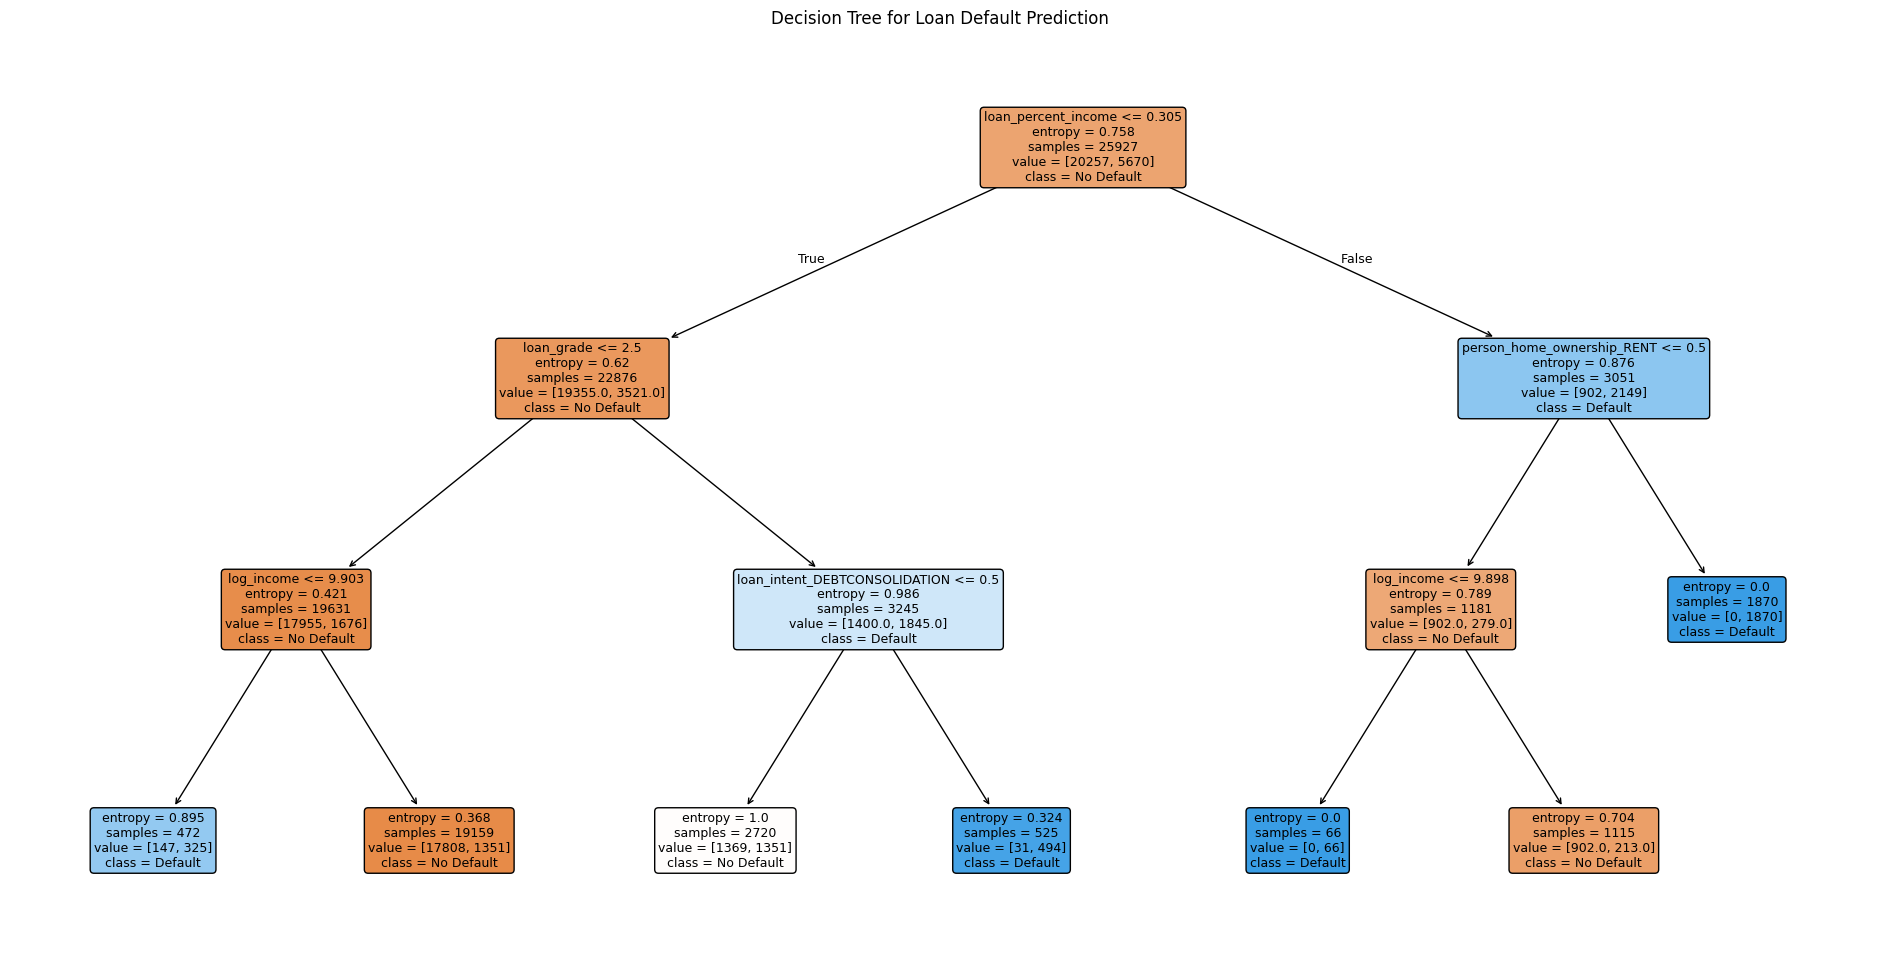

Saved: outputs/tree_depth3.png


In [5]:

# Task 6(a): Visualise the depth-3 decision tree

plt.figure(figsize=(24, 12))

plot_tree(
    tree3,
    feature_names=X_train.columns,
    class_names=["No Default", "Default"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree for Loan Default Prediction")

# Save the required graph
plt.savefig(
    "outputs/tree_depth3.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Saved: outputs/tree_depth3.png")



### Task 6(a): Explanation of the Root Split

The first split in my decision tree uses the feature `loan_percent_income` with a threshold of 0.305.

This means the model first separates borrowers whose loan amount is 30.5% or less of their income from borrowers whose loan amount is above 30.5% of their income.

This feature helps the model distinguish different patterns of loan default risk.

The depth-3 tree achieved a training accuracy of 88.07% and a testing accuracy of 88.00%.

The small difference suggests that the depth-3 model does not show obvious overfitting.



## Task 6(a): Decision Tree Depth Comparison

In this section, I compare decision trees with maximum depths from 1 to 15 to investigate the relationship between model complexity, training accuracy and testing accuracy.


DECISION TREE DEPTH COMPARISON


,depth,train_accuracy,test_accuracy
0,1,0.8294,0.8295
1,2,0.8706,0.8701
2,3,0.8807,0.8800
3,4,0.9035,0.9044
4,5,0.9176,0.9219
5,6,0.9288,0.9327
6,7,0.9310,0.9338
7,8,0.9352,0.9372
8,9,0.9357,0.9364
9,10,0.9371,0.9369



Best tested depth: 8
Best test accuracy: 0.9372


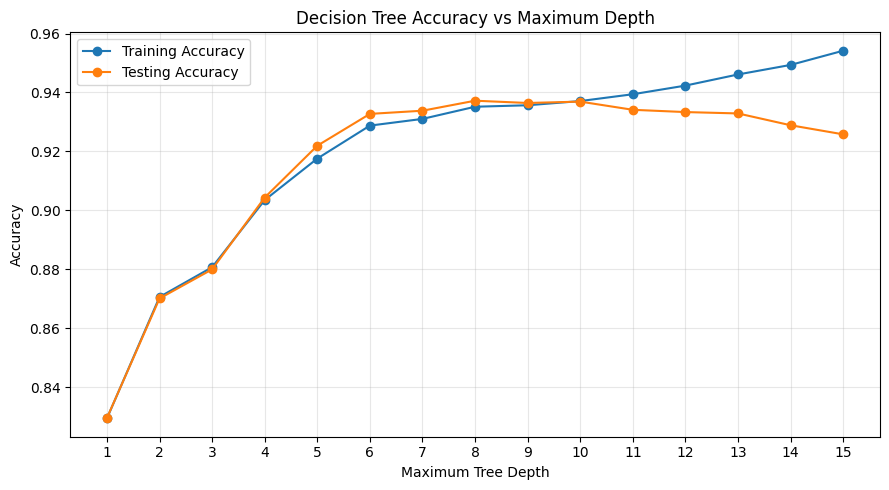


Saved: outputs/depth_curve.png


In [6]:

# Task 6(a): Compare decision tree depths 1 to 15

from sklearn.tree import DecisionTreeClassifier

# Store accuracy results for every depth
depth_data = []

# Train trees with maximum depths from 1 to 15
for depth in range(1, 16):

    # Create a decision tree using entropy
    model = DecisionTreeClassifier(
        max_depth=depth,
        criterion="entropy",
        random_state=42
    )

    # Train using training records
    model.fit(X_train, y_train)

    # Calculate training and testing accuracy
    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)

    # Save the results
    depth_data.append({
        "depth": depth,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

# Create the required results DataFrame
depth_results = pd.DataFrame(depth_data)

# Display all results
print("DECISION TREE DEPTH COMPARISON")
display(depth_results.round(4))

# Find the depth with highest testing accuracy
best_row = depth_results.loc[
    depth_results["test_accuracy"].idxmax()
]

print("\nBest tested depth:", int(best_row["depth"]))
print("Best test accuracy:",
      round(best_row["test_accuracy"], 4))

# Plot training and testing accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    depth_results["depth"],
    depth_results["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_results["depth"],
    depth_results["test_accuracy"],
    marker="o",
    label="Testing Accuracy"
)

# Add labels
plt.title("Decision Tree Accuracy vs Maximum Depth")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")

plt.xticks(range(1, 16))
plt.legend()
plt.grid(alpha=0.3)

# Save the required graph
plt.tight_layout()
plt.savefig("outputs/depth_curve.png", dpi=150)

# Show the graph
plt.show()

print("\nSaved: outputs/depth_curve.png")



## Task 6(b): Exam Skill — Entropy and Information Gain

This section calculates entropy and information gain using NumPy.

I calculate the information gain of my decision tree's first split and compare it with a split on the median borrower income.


In [7]:

# Task 6(b): Calculate entropy and information gain

import numpy as np

# Calculate entropy for a set of class labels
def entropy(y):
    values = np.asarray(y)

    if len(values) == 0:
        return 0.0

    counts = np.unique(values, return_counts=True)[1]
    probabilities = counts / counts.sum()

    return -np.sum(probabilities * np.log2(probabilities))


# Calculate the information gain of a split
def information_gain(y_parent, y_left, y_right):

    total = len(y_parent)

    if total == 0:
        return 0.0

    left_weight = len(y_left) / total
    right_weight = len(y_right) / total

    parent_entropy = entropy(y_parent)

    weighted_entropy = (
        left_weight * entropy(y_left)
        + right_weight * entropy(y_right)
    )

    return parent_entropy - weighted_entropy


# Get the actual first split from the fitted tree
root_index = tree3.tree_.feature[0]
root_feature = X_train.columns[root_index]
root_threshold = tree3.tree_.threshold[0]

# Get the training labels
labels = y_train.to_numpy()

# Divide records using the tree's first split
root_mask = (
    X_train[root_feature].to_numpy() <= root_threshold
)

# Calculate the root information gain
ig_root = information_gain(
    labels,
    labels[root_mask],
    labels[~root_mask]
)

# Compare with a split on median borrower income
income_median = X_train["person_income"].median()

income_mask = (
    X_train["person_income"].to_numpy() <= income_median
)

ig_income = information_gain(
    labels,
    labels[income_mask],
    labels[~income_mask]
)

# Display results
print("INFORMATION GAIN RESULTS")

print("Root feature:", root_feature)
print("Root threshold:", round(root_threshold, 4))

print("\nOriginal entropy:", round(entropy(labels), 6))
print("Root information gain:", round(ig_root, 6))

print("\nMedian income:", income_median)
print("Income split information gain:", round(ig_income, 6))

print("\nRoot has higher or equal gain:",
      ig_root >= ig_income - 1e-10)

print("\nInformation gain calculation completed!")


INFORMATION GAIN RESULTS
Root feature: loan_percent_income
Root threshold: 0.305

Original entropy: 0.75777
Root information gain: 0.108049

Median income: 55000.0
Income split information gain: 0.033921

Root has higher or equal gain: True

Information gain calculation completed!



## Task 6(c): Random Forest and Gradient Boosting

In this section, I train a Random Forest and a Gradient Boosting classifier to predict loan defaults.

I compare their testing accuracy and F1-score with the depth-3 Decision Tree to determine whether ensemble models improve prediction performance.


In [8]:

# Task 6(c): Train and compare ensemble classifiers

# Import ensemble models and evaluation metrics
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import accuracy_score, f1_score

# 1. Train Random Forest using 100 decision trees
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

print("Random Forest training completed!")

# 2. Train Gradient Boosting using 100 estimators
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb.fit(X_train, y_train)

print("Gradient Boosting training completed!")

# 3. Collect the three trained models
models_trees = {
    "Decision Tree (Depth 3)": tree3,
    "Random Forest": rf,
    "Gradient Boosting": gb
}

# 4. Calculate test accuracy and F1-score
tree_comparison = []

for name, model in models_trees.items():

    # Predict loan defaults
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    # Store the model results
    tree_comparison.append({
        "Model": name,
        "Accuracy": accuracy,
        "F1": f1
    })

# 5. Create the required results variable
results_trees = pd.DataFrame(tree_comparison)

# Display the results
print("\nDECISION TREE AND ENSEMBLE COMPARISON")
display(results_trees.round(4))

# Identify the highest F1-score
best_model = results_trees.loc[
    results_trees["F1"].idxmax(), "Model"
]

print("\nHighest F1-score model:", best_model)
print("\nTask 6(c) completed successfully!")


Random Forest training completed!
Gradient Boosting training completed!

DECISION TREE AND ENSEMBLE COMPARISON


,Model,Accuracy,F1
0,Decision Tree (Depth 3),0.8800,0.6381
1,Random Forest,0.9363,0.8333
2,Gradient Boosting,0.9326,0.8254



Highest F1-score model: Random Forest

Task 6(c) completed successfully!



## Task 6(d): Random Forest Feature Importance

This section identifies the ten most important features used by the Random Forest model to predict loan defaults.

I also examine which of the five most important features a SACCO loan officer can check using information provided during a loan application.


TOP 10 IMPORTANT FEATURES


,0
loan_percent_income,0.2037
loan_grade,0.1661
person_income,0.1070
log_income,0.1063
loan_amnt,0.0766
person_emp_length,0.0579
person_home_ownership_RENT,0.0544
person_age,0.0445
cb_person_cred_hist_length,0.0345
person_home_ownership_MORTGAGE,0.0272



TOP FIVE FEATURES:
loan_percent_income: 0.2037
loan_grade: 0.1661
person_income: 0.1070
log_income: 0.1063
loan_amnt: 0.0766


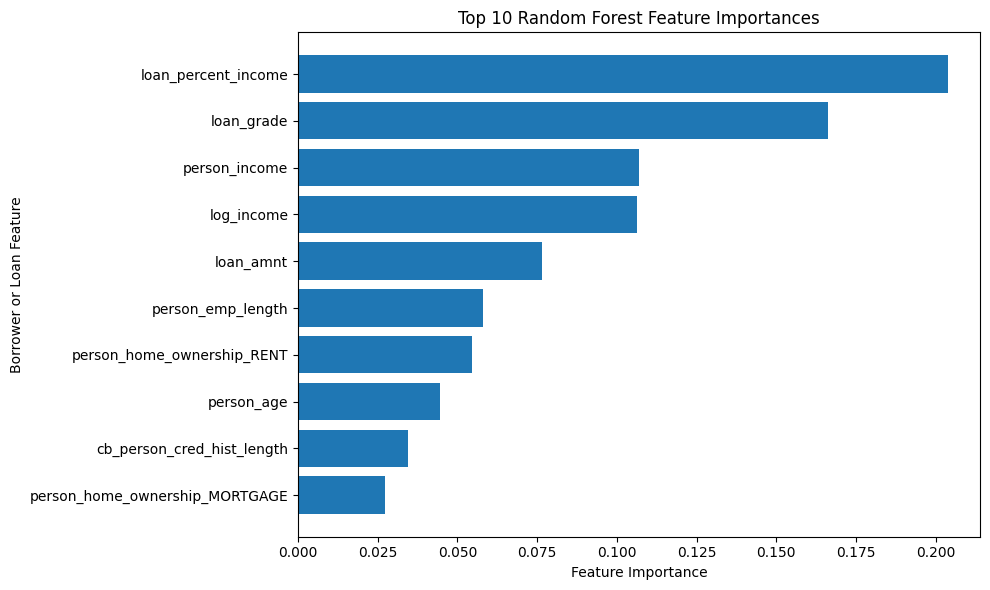


Total feature importance: 1.0
Saved: outputs/feature_importance.png
Feature importance analysis completed!


In [9]:

# Task 6(d): Calculate Random Forest feature importance

# Extract feature importance values from Random Forest
importances = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Display the ten most important features
print("TOP 10 IMPORTANT FEATURES")
display(importances.head(10).round(4))

# Display the five most important features separately
print("\nTOP FIVE FEATURES:")

for feature, importance in importances.head(5).items():
    print(f"{feature}: {importance:.4f}")

# Prepare the ten features for plotting
top_ten = importances.head(10).sort_values()

# Create the horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_ten.index,
    top_ten.values
)

# Add title and labels
plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("Borrower or Loan Feature")

# Save the required graph
plt.tight_layout()
plt.savefig(
    "outputs/feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)

# Display the graph
plt.show()

print("\nTotal feature importance:",
      round(importances.sum(), 4))

print("Saved: outputs/feature_importance.png")
print("Feature importance analysis completed!")



### Task 6(d): Interpretation of Feature Importance

The Random Forest identified loan_percent_income as the most important feature, with an importance of 0.2037.

The other four leading features were loan_grade (0.1661), person_income (0.1070), log_income (0.1063) and loan_amnt (0.0766).

A loan officer can verify person_income using income documents and loan_amnt from the requested loan amount.

The loan_percent_income ratio can be calculated from the applicant's income and requested loan amount. The log_income feature can also be calculated from income.

Loan_grade requires special care because it may be assigned internally rather than supplied on an application. We must confirm it is available before making a prediction to avoid data leakage.


## Part a) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [10]:
# a1. <what this cell does>


## Part b) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [11]:
# b1. <what this cell does>


## Part c) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [12]:
# c1. <what this cell does>


## Written answer


## Task 6: Written Answer — Decision Trees and Ensembles

I trained a Decision Tree, Random Forest and Gradient Boosting classifier to predict loan defaults.

The depth-3 Decision Tree achieved a test accuracy of 88.00% and an F1-score of 0.6381.

When I tested tree depths from 1 to 15, the highest test accuracy was 93.72% at depth 8. Overfitting became more noticeable around depth 11, when training accuracy continued increasing while testing accuracy declined.

Random Forest achieved 93.63% accuracy and an F1-score of 0.8333, while Gradient Boosting achieved 93.26% accuracy and an F1-score of 0.8254.

Random Forest performed better than the depth-3 single tree because combining many trees can reduce the effect of individual trees learning noise in the training data. However, the depth-8 tree had slightly higher test accuracy than the forest, so ensembles do not automatically outperform every individual tree.

The first split in the depth-3 tree used loan_percent_income at a threshold of 0.305. Its information gain was 0.108049, compared with 0.033921 for splitting person_income at its median of 55,000.

The most important Random Forest feature was loan_percent_income, followed by loan_grade, person_income, log_income and loan_amnt.

These features help explain the model's predictions, but their importance scores do not establish causation. Loan_grade should also be checked for availability at application time before the model is deployed.


## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [13]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 6
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [14]:
# Paste the self-check cell from Moodle here
